DATA 266 Lab 2 - Part 2: Diffusion Fine-Tuning
Cleans a licensed captioned Hugging Face dataset, makes the seed-266 90/10 split, trains two comparable LoRA runs, generates 20 fixed prompts with seeds 0 and 1, and computes metrics only from actual outputs.

In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Please enable a T4 GPU runtime.")

CUDA available: True
GPU: Tesla T4


In [2]:
%pip install -q datasets diffusers transformers accelerate peft safetensors torchvision torchmetrics lpips

In [3]:
import os
import time
import json
import random
import hashlib
import platform
import subprocess

from pathlib import Path

import numpy as np
import torch

SEED = 5996

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print({
    "python": platform.python_version(),
    "torch": torch.__version__,
    "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU",
    "seed": SEED,
    "commit": subprocess.run(
        ["git", "rev-parse", "HEAD"],
        capture_output=True,
        text=True
    ).stdout.strip() or "not-a-git-repository"
})

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'seed': 5996, 'commit': 'not-a-git-repository'}


In [4]:
from datasets import load_dataset

DATASET_ID = "lambdalabs/naruto-blip-captions"

dataset = load_dataset(
    DATASET_ID,
    split="train"
)

print(dataset)
print("Columns:", dataset.column_names)
print("Number of images:", len(dataset))

Repo card metadata block was not found. Setting CardData to empty.


Dataset({
    features: ['image', 'text'],
    num_rows: 1221
})
Columns: ['image', 'text']
Number of images: 1221


In [5]:
image_column = None
caption_column = None

for column in dataset.column_names:
    if column.lower() in ["image", "img"]:
        image_column = column

    if column.lower() in [
        "text",
        "caption",
        "prompt",
        "blip_caption"
    ]:
        caption_column = column

print("Image column:", image_column)
print("Caption column:", caption_column)

if image_column is None or caption_column is None:
    raise ValueError(
        "Could not identify the image and caption columns."
    )

Image column: image
Caption column: text


Caption:
a man with dark hair and brown eyes


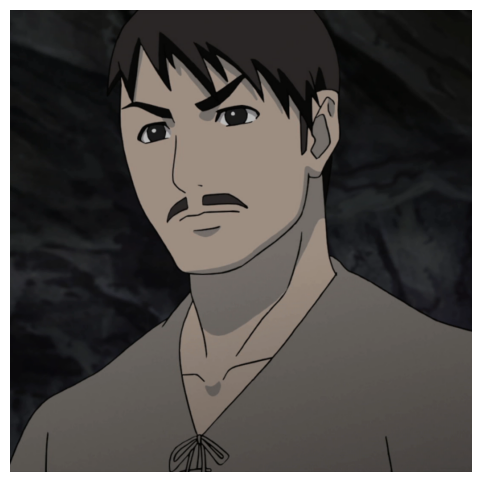

In [6]:
import matplotlib.pyplot as plt

example = dataset[0]

print("Caption:")
print(example[caption_column])

plt.figure(figsize=(6, 6))
plt.imshow(example[image_column].convert("RGB"))
plt.axis("off")
plt.show()

In [7]:
clean_items = []
seen_hashes = set()

corrupted_count = 0
duplicate_count = 0

for index, example in enumerate(dataset):

    try:
        image = example[image_column].convert("RGB")
        caption = str(example[caption_column]).strip()

        if not caption:
            corrupted_count += 1
            continue

        image_hash = hashlib.sha256(
            image.tobytes()
        ).hexdigest()

        if image_hash in seen_hashes:
            duplicate_count += 1
            continue

        seen_hashes.add(image_hash)

        clean_items.append({
            "image": image,
            "text": caption,
            "original_index": index
        })

    except Exception:
        corrupted_count += 1

print({
    "original_images": len(dataset),
    "clean_images": len(clean_items),
    "corrupted_removed": corrupted_count,
    "duplicates_removed": duplicate_count
})

{'original_images': 1221, 'clean_images': 1221, 'corrupted_removed': 0, 'duplicates_removed': 0}


In [8]:
rng = np.random.default_rng(SEED)

rng.shuffle(clean_items)

split_index = int(0.90 * len(clean_items))

train_items = clean_items[:split_index]
test_items = clean_items[split_index:]

print({
    "train_images": len(train_items),
    "test_images": len(test_items),
    "train_percentage": round(
        len(train_items) / len(clean_items) * 100,
        2
    ),
    "test_percentage": round(
        len(test_items) / len(clean_items) * 100,
        2
    ),
    "seed": SEED
})

{'train_images': 1098, 'test_images': 123, 'train_percentage': 89.93, 'test_percentage': 10.07, 'seed': 5996}


In [9]:
output_dir = Path("/content/part2_outputs")
output_dir.mkdir(exist_ok=True)

data_report = {
    "dataset_id": DATASET_ID,
    "dataset_license": "Verify and record the license from the Hugging Face dataset page.",
    "seed": SEED,
    "original_images": len(dataset),
    "clean_images": len(clean_items),
    "corrupted_removed": corrupted_count,
    "duplicates_removed": duplicate_count,
    "training_images": len(train_items),
    "test_images": len(test_items),
    "image_size_required": "512x512"
}

with open(output_dir / "data_preparation_report.json", "w") as file:
    json.dump(data_report, file, indent=2)

print(json.dumps(data_report, indent=2))

{
  "dataset_id": "lambdalabs/naruto-blip-captions",
  "dataset_license": "Verify and record the license from the Hugging Face dataset page.",
  "seed": 5996,
  "original_images": 1221,
  "clean_images": 1221,
  "corrupted_removed": 0,
  "duplicates_removed": 0,
  "training_images": 1098,
  "test_images": 123,
  "image_size_required": "512x512"
}


In [10]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from transformers import CLIPTokenizer, CLIPTextModel

from diffusers import (
    AutoencoderKL,
    UNet2DConditionModel,
    DDPMScheduler
)

BASE_MODEL = "runwayml/stable-diffusion-v1-5"

tokenizer = CLIPTokenizer.from_pretrained(
    BASE_MODEL,
    subfolder="tokenizer"
)

text_encoder = CLIPTextModel.from_pretrained(
    BASE_MODEL,
    subfolder="text_encoder",
    torch_dtype=torch.float16
).to(DEVICE)

vae = AutoencoderKL.from_pretrained(
    BASE_MODEL,
    subfolder="vae",
    torch_dtype=torch.float16
).to(DEVICE)

unet = UNet2DConditionModel.from_pretrained(
    BASE_MODEL,
    subfolder="unet",
    torch_dtype=torch.float16
).to(DEVICE)

noise_scheduler = DDPMScheduler.from_pretrained(
    BASE_MODEL,
    subfolder="scheduler"
)

print("Stable Diffusion components loaded successfully.")

W1117 19:00:37.425000 243898 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1117 19:00:37.492000 243898 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Stable Diffusion components loaded successfully.


In [11]:
vae.requires_grad_(False)
text_encoder.requires_grad_(False)

vae.eval()
text_encoder.eval()

print("VAE frozen:", not any(
    parameter.requires_grad
    for parameter in vae.parameters()
))

print("Text encoder frozen:", not any(
    parameter.requires_grad
    for parameter in text_encoder.parameters()
))

VAE frozen: True
Text encoder frozen: True


In [12]:
class DiffusionCaptionDataset(Dataset):

    def __init__(self, items, tokenizer, training=True):
        self.items = items
        self.tokenizer = tokenizer

        transforms_list = [
            transforms.Resize(
                (512, 512),
                interpolation=transforms.InterpolationMode.BILINEAR
            )
        ]

        if training:
            transforms_list.append(
                transforms.RandomHorizontalFlip()
            )

        transforms_list.extend([
            transforms.ToTensor(),
            transforms.Normalize(
                [0.5, 0.5, 0.5],
                [0.5, 0.5, 0.5]
            )
        ])

        self.image_transform = transforms.Compose(
            transforms_list
        )

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        item = self.items[index]

        image = item["image"].convert("RGB")
        caption = item["text"]

        pixel_values = self.image_transform(image)

        input_ids = self.tokenizer(
            caption,
            padding="max_length",
            truncation=True,
            max_length=self.tokenizer.model_max_length,
            return_tensors="pt"
        ).input_ids[0]

        return {
            "pixel_values": pixel_values,
            "input_ids": input_ids,
            "caption": caption
        }

In [13]:
BATCH_SIZE = 1

train_dataset = DiffusionCaptionDataset(
    train_items,
    tokenizer,
    training=True
)

test_dataset = DiffusionCaptionDataset(
    test_items,
    tokenizer,
    training=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training images: 1098
Testing images: 123
Training batches: 1098
Testing batches: 123


In [14]:
batch = next(iter(train_loader))

print("Pixel values shape:", batch["pixel_values"].shape)
print("Input IDs shape:", batch["input_ids"].shape)
print("Example caption:", batch["caption"][0])

Pixel values shape: torch.Size([1, 3, 512, 512])
Input IDs shape: torch.Size([1, 77])
Example caption: a girl sitting on the ground with her hands on her knees


In [15]:
from diffusers.models.attention_processor import LoRAAttnProcessor

def get_attention_hidden_size(
    processor_name,
    unet_model
):
    if processor_name.startswith("mid_block"):
        return unet_model.config.block_out_channels[-1]

    if processor_name.startswith("up_blocks"):
        block_id = int(processor_name.split(".")[1])
        reversed_channels = list(
            reversed(unet_model.config.block_out_channels)
        )
        return reversed_channels[block_id]

    if processor_name.startswith("down_blocks"):
        block_id = int(processor_name.split(".")[1])
        return unet_model.config.block_out_channels[block_id]

    return unet_model.config.block_out_channels[-1]


def add_lora_layers(unet_model, rank):
    unet_model.requires_grad_(False)

    lora_processors = {}

    for name in unet_model.attn_processors.keys():

        hidden_size = get_attention_hidden_size(
            name,
            unet_model
        )

        cross_attention_dim = (
            None
            if name.endswith("attn1.processor")
            else unet_model.config.cross_attention_dim
        )

        lora_processors[name] = LoRAAttnProcessor(
            hidden_size=hidden_size,
            cross_attention_dim=cross_attention_dim,
            rank=rank
        )

    unet_model.set_attn_processor(lora_processors)

    trainable_parameters = [
        parameter
        for parameter in unet_model.parameters()
        if parameter.requires_grad
    ]

    return trainable_parameters

In [16]:
from diffusers import UNet2DConditionModel

unet = UNet2DConditionModel.from_pretrained(
    BASE_MODEL,
    subfolder="unet",
    torch_dtype=torch.float16
).to(DEVICE)

print("UNet reloaded successfully.")

UNet reloaded successfully.


In [17]:
%pip install -q --upgrade "torchao>=0.16.0"

In [18]:
import importlib.metadata

print("torchao version:", importlib.metadata.version("torchao"))

torchao version: 0.18.0


In [19]:
from peft import LoraConfig

LORA_RANK = 4

lora_config = LoraConfig(
    r=LORA_RANK,
    lora_alpha=LORA_RANK,
    target_modules=[
        "to_q",
        "to_k",
        "to_v",
        "to_out.0"
    ],
    lora_dropout=0.0,
    bias="none"
)

unet.add_adapter(lora_config)

trainable_parameters = [
    parameter
    for parameter in unet.parameters()
    if parameter.requires_grad
]

trainable_count = sum(
    parameter.numel()
    for parameter in trainable_parameters
)

total_count = sum(
    parameter.numel()
    for parameter in unet.parameters()
)

print("LoRA rank:", LORA_RANK)
print("Trainable parameters:", trainable_count)
print("Total UNet parameters:", total_count)
print(
    "Trainable percentage:",
    round(100 * trainable_count / total_count, 4),
    "%"
)

LoRA rank: 4
Trainable parameters: 797184
Total UNet parameters: 860318148
Trainable percentage: 0.0927 %


In [20]:
trainable_names = [
    name
    for name, parameter in unet.named_parameters()
    if parameter.requires_grad
]

print("Number of trainable tensors:", len(trainable_names))
print("\nFirst trainable parameters:")

for name in trainable_names[:10]:
    print(name)

Number of trainable tensors: 256

First trainable parameters:
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_q.lora_A.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_q.lora_B.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_k.lora_A.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_k.lora_B.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_v.lora_A.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_v.lora_B.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_out.0.lora_A.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn1.to_out.0.lora_B.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_q.lora_A.default.weight
down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_q.lora_B.default.weight


In [21]:
from torch.nn.utils import clip_grad_norm_

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=1e-4,
    betas=(0.9, 0.999),
    weight_decay=1e-2,
    eps=1e-8
)

unet.train()

print("Optimizer created.")

Optimizer created.


In [22]:
batch = next(iter(train_loader))

pixel_values = batch["pixel_values"].to(
    DEVICE,
    dtype=torch.float16
)

input_ids = batch["input_ids"].to(DEVICE)

# Encode images into latent space
with torch.no_grad():

    latents = vae.encode(
        pixel_values
    ).latent_dist.sample()

    latents = latents * vae.config.scaling_factor

    encoder_hidden_states = text_encoder(
        input_ids
    )[0]

# Add random noise
noise = torch.randn_like(latents)

timesteps = torch.randint(
    0,
    noise_scheduler.config.num_train_timesteps,
    (latents.shape[0],),
    device=DEVICE
).long()

noisy_latents = noise_scheduler.add_noise(
    latents,
    noise,
    timesteps
)

optimizer.zero_grad(set_to_none=True)

# Forward pass
with torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):

    noise_prediction = unet(
        noisy_latents,
        timesteps,
        encoder_hidden_states=encoder_hidden_states
    ).sample

    loss = torch.nn.functional.mse_loss(
        noise_prediction.float(),
        noise.float()
    )

# Backpropagation
loss.backward()

clip_grad_norm_(
    trainable_parameters,
    max_norm=1.0
)

optimizer.step()

print("One training step completed.")
print("Loss:", float(loss.detach().cpu()))

One training step completed.
Loss: 0.0842883437871933


In [23]:
if torch.cuda.is_available():
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 3)
    print("Peak GPU memory:", round(peak_memory, 3), "GB")

Peak GPU memory: 3.629 GB


In [24]:
import gc
from peft import LoraConfig, get_peft_model_state_dict

def create_lora_unet(rank):

    fresh_unet = UNet2DConditionModel.from_pretrained(
        BASE_MODEL,
        subfolder="unet",
        torch_dtype=torch.float16
    ).to(DEVICE)

    lora_config = LoraConfig(
        r=rank,
        lora_alpha=rank,
        target_modules=[
            "to_q",
            "to_k",
            "to_v",
            "to_out.0"
        ],
        lora_dropout=0.0,
        bias="none"
    )

    fresh_unet.add_adapter(lora_config)

    trainable_parameters = [
        parameter
        for parameter in fresh_unet.parameters()
        if parameter.requires_grad
    ]

    # Keep LoRA weights in FP32 for stable gradient scaling
    for parameter in trainable_parameters:
        parameter.data = parameter.data.float()

    return fresh_unet, trainable_parameters

In [25]:
def train_lora_run_stable(
    run_name,
    rank,
    max_steps=1000,
    learning_rate=1e-5
):
    print(f"Starting stable run: {run_name}")
    print(f"LoRA rank: {rank}")
    print(f"Learning rate: {learning_rate}")
    print(f"Maximum steps: {max_steps}")

    run_dir = output_dir / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    # Create a completely fresh UNet and LoRA adapter
    run_unet, run_parameters = create_lora_unet(rank)

    optimizer = torch.optim.AdamW(
        run_parameters,
        lr=learning_rate,
        betas=(0.9, 0.999),
        weight_decay=1e-4,
        eps=1e-6
    )

    scaler = torch.cuda.amp.GradScaler()

    run_unet.train()
    data_iterator = iter(train_loader)

    losses = []
    step = 0
    start_time = time.perf_counter()

    while step < max_steps:

        try:
            batch = next(data_iterator)
        except StopIteration:
            data_iterator = iter(train_loader)
            batch = next(data_iterator)

        pixel_values = batch["pixel_values"].to(
            DEVICE,
            dtype=torch.float16
        )

        input_ids = batch["input_ids"].to(DEVICE)

        with torch.no_grad():

            latents = vae.encode(
                pixel_values
            ).latent_dist.sample()

            latents = (
                latents *
                vae.config.scaling_factor
            )

            encoder_hidden_states = text_encoder(
                input_ids
            )[0]

        noise = torch.randn_like(latents)

        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],),
            device=DEVICE
        ).long()

        noisy_latents = noise_scheduler.add_noise(
            latents,
            noise,
            timesteps
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(
            dtype=torch.float16
        ):

            noise_prediction = run_unet(
                noisy_latents,
                timesteps,
                encoder_hidden_states=encoder_hidden_states
            ).sample

            loss = torch.nn.functional.mse_loss(
                noise_prediction.float(),
                noise.float()
            )

        # Stop immediately if NaN or infinity appears
        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss detected at step {step + 1}: {loss.item()}"
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            run_parameters,
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        step += 1

        loss_value = float(loss.detach().cpu())
        losses.append(loss_value)

        if step == 1 or step % 50 == 0:
            elapsed = time.perf_counter() - start_time

            print(
                f"Step {step}/{max_steps} | "
                f"Loss: {loss_value:.6f} | "
                f"Time: {elapsed / 60:.2f} minutes"
            )

        if step % 250 == 0:
            checkpoint_path = run_dir / f"checkpoint_{step}.pt"

            adapter_state = get_peft_model_state_dict(
                run_unet
            )

            torch.save(
                adapter_state,
                checkpoint_path
            )

            print("Saved checkpoint:", checkpoint_path)

    total_time = time.perf_counter() - start_time

    final_adapter_path = run_dir / "final_adapter.pt"

    final_adapter_state = get_peft_model_state_dict(
        run_unet
    )

    torch.save(
        final_adapter_state,
        final_adapter_path
    )

    peak_memory_gb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    statistics = {
        "run_name": run_name,
        "lora_rank": rank,
        "steps": max_steps,
        "learning_rate": learning_rate,
        "batch_size": BATCH_SIZE,
        "image_resolution": "512x512",
        "training_seconds": total_time,
        "training_minutes": total_time / 60,
        "peak_gpu_memory_gb": peak_memory_gb,
        "trainable_parameters": sum(
            parameter.numel()
            for parameter in run_parameters
        ),
        "final_loss": losses[-1],
        "average_loss": float(np.mean(losses)),
        "seed": SEED
    }

    with open(run_dir / "training_statistics.json", "w") as file:
        json.dump(statistics, file, indent=2)

    print("\nStable training completed.")
    print(json.dumps(statistics, indent=2))

    del run_unet
    del optimizer
    del scaler

    gc.collect()
    torch.cuda.empty_cache()

    return statistics

In [26]:
stable_test = train_lora_run_stable(
    run_name="lora_rank4_stable_test",
    rank=4,
    max_steps=20,
    learning_rate=1e-5
)

Starting stable run: lora_rank4_stable_test
LoRA rank: 4
Learning rate: 1e-05
Maximum steps: 20


/tmp/ipykernel_243898/4286806497.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_243898/4286806497.py:86: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Step 1/20 | Loss: 0.013904 | Time: 0.01 minutes

Stable training completed.
{
  "run_name": "lora_rank4_stable_test",
  "lora_rank": 4,
  "steps": 20,
  "learning_rate": 1e-05,
  "batch_size": 1,
  "image_resolution": "512x512",
  "training_seconds": 7.83975094500056,
  "training_minutes": 0.13066251575000934,
  "peak_gpu_memory_gb": 4.759192943572998,
  "trainable_parameters": 797184,
  "final_loss": 0.2304266393184662,
  "average_loss": 0.1002224430674687,
  "seed": 5996
}


In [27]:
run1_statistics = train_lora_run_stable(
    run_name="lora_rank4_final",
    rank=4,
    max_steps=1000,
    learning_rate=1e-5
)

Starting stable run: lora_rank4_final
LoRA rank: 4
Learning rate: 1e-05
Maximum steps: 1000


/tmp/ipykernel_243898/4286806497.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_243898/4286806497.py:86: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Step 1/1000 | Loss: 0.004040 | Time: 0.01 minutes
Step 50/1000 | Loss: 0.076304 | Time: 0.34 minutes
Step 100/1000 | Loss: 0.068785 | Time: 0.69 minutes
Step 150/1000 | Loss: 0.013667 | Time: 1.02 minutes
Step 200/1000 | Loss: 0.054527 | Time: 1.34 minutes
Step 250/1000 | Loss: 0.022851 | Time: 1.67 minutes
Saved checkpoint: /content/part2_outputs/lora_rank4_final/checkpoint_250.pt
Step 300/1000 | Loss: 0.049532 | Time: 2.00 minutes
Step 350/1000 | Loss: 0.021101 | Time: 2.34 minutes
Step 400/1000 | Loss: 0.194387 | Time: 2.67 minutes
Step 450/1000 | Loss: 0.063877 | Time: 3.00 minutes
Step 500/1000 | Loss: 0.080292 | Time: 3.33 minutes
Saved checkpoint: /content/part2_outputs/lora_rank4_final/checkpoint_500.pt
Step 550/1000 | Loss: 0.138093 | Time: 3.66 minutes
Step 600/1000 | Loss: 0.367694 | Time: 4.00 minutes
Step 650/1000 | Loss: 0.160479 | Time: 4.33 minutes
Step 700/1000 | Loss: 0.074399 | Time: 4.66 minutes
Step 750/1000 | Loss: 0.317203 | Time: 4.98 minutes
Saved checkpoint: /

In [28]:
with open(
    "/content/part2_outputs/lora_rank4_final/training_statistics.json",
    "r"
) as file:
    run1_statistics = json.load(file)

print(json.dumps(run1_statistics, indent=2))

assert np.isfinite(run1_statistics["final_loss"])
assert np.isfinite(run1_statistics["average_loss"])

print("Rank-4 training results are valid.")

{
  "run_name": "lora_rank4_final",
  "lora_rank": 4,
  "steps": 1000,
  "learning_rate": 1e-05,
  "batch_size": 1,
  "image_resolution": "512x512",
  "training_seconds": 398.69455396999547,
  "training_minutes": 6.644909232833258,
  "peak_gpu_memory_gb": 4.759192943572998,
  "trainable_parameters": 797184,
  "final_loss": 0.15763378143310547,
  "average_loss": 0.09209477222221904,
  "seed": 5996
}
Rank-4 training results are valid.


In [29]:
SEED = 266

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Fixed seed:", SEED)

Fixed seed: 266


In [30]:
run1_seed266_statistics = train_lora_run_stable(
    run_name="lora_rank4_seed266",
    rank=4,
    max_steps=1000,
    learning_rate=1e-5
)

Starting stable run: lora_rank4_seed266
LoRA rank: 4
Learning rate: 1e-05
Maximum steps: 1000


/tmp/ipykernel_243898/4286806497.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_243898/4286806497.py:86: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Step 1/1000 | Loss: 0.006098 | Time: 0.01 minutes
Step 50/1000 | Loss: 0.009966 | Time: 0.33 minutes
Step 100/1000 | Loss: 0.181368 | Time: 0.67 minutes
Step 150/1000 | Loss: 0.005998 | Time: 1.00 minutes
Step 200/1000 | Loss: 0.111392 | Time: 1.33 minutes
Step 250/1000 | Loss: 0.032115 | Time: 1.66 minutes
Saved checkpoint: /content/part2_outputs/lora_rank4_seed266/checkpoint_250.pt
Step 300/1000 | Loss: 0.025528 | Time: 1.99 minutes
Step 350/1000 | Loss: 0.057107 | Time: 2.32 minutes
Step 400/1000 | Loss: 0.028102 | Time: 2.65 minutes
Step 450/1000 | Loss: 0.126524 | Time: 2.98 minutes
Step 500/1000 | Loss: 0.003896 | Time: 3.31 minutes
Saved checkpoint: /content/part2_outputs/lora_rank4_seed266/checkpoint_500.pt
Step 550/1000 | Loss: 0.042423 | Time: 3.64 minutes
Step 600/1000 | Loss: 0.218435 | Time: 3.97 minutes
Step 650/1000 | Loss: 0.085255 | Time: 4.31 minutes
Step 700/1000 | Loss: 0.478255 | Time: 4.64 minutes
Step 750/1000 | Loss: 0.086824 | Time: 4.97 minutes
Saved checkpoin

In [31]:
print(json.dumps(run1_seed266_statistics, indent=2))

assert run1_seed266_statistics["seed"] == 266
assert np.isfinite(run1_seed266_statistics["final_loss"])

print("Rank-4 final run is valid and reproducible.")

{
  "run_name": "lora_rank4_seed266",
  "lora_rank": 4,
  "steps": 1000,
  "learning_rate": 1e-05,
  "batch_size": 1,
  "image_resolution": "512x512",
  "training_seconds": 397.55204245299683,
  "training_minutes": 6.625867374216614,
  "peak_gpu_memory_gb": 4.759192943572998,
  "trainable_parameters": 797184,
  "final_loss": 0.08345091342926025,
  "average_loss": 0.09112555239372887,
  "seed": 266
}
Rank-4 final run is valid and reproducible.


In [32]:
SEED = 266

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

run2_statistics = train_lora_run_stable(
    run_name="lora_rank16_seed266",
    rank=16,
    max_steps=1000,
    learning_rate=1e-5
)

Starting stable run: lora_rank16_seed266
LoRA rank: 16
Learning rate: 1e-05
Maximum steps: 1000


/tmp/ipykernel_243898/4286806497.py:30: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_243898/4286806497.py:86: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(


Step 1/1000 | Loss: 0.004540 | Time: 0.01 minutes
Step 50/1000 | Loss: 0.008128 | Time: 0.33 minutes
Step 100/1000 | Loss: 0.152137 | Time: 0.66 minutes
Step 150/1000 | Loss: 0.006163 | Time: 0.99 minutes
Step 200/1000 | Loss: 0.166803 | Time: 1.32 minutes
Step 250/1000 | Loss: 0.047465 | Time: 1.65 minutes
Saved checkpoint: /content/part2_outputs/lora_rank16_seed266/checkpoint_250.pt
Step 300/1000 | Loss: 0.023395 | Time: 1.98 minutes
Step 350/1000 | Loss: 0.042915 | Time: 2.31 minutes
Step 400/1000 | Loss: 0.043059 | Time: 2.64 minutes
Step 450/1000 | Loss: 0.277882 | Time: 2.97 minutes
Step 500/1000 | Loss: 0.004389 | Time: 3.30 minutes
Saved checkpoint: /content/part2_outputs/lora_rank16_seed266/checkpoint_500.pt
Step 550/1000 | Loss: 0.068728 | Time: 3.63 minutes
Step 600/1000 | Loss: 0.368604 | Time: 3.97 minutes
Step 650/1000 | Loss: 0.080916 | Time: 4.30 minutes
Step 700/1000 | Loss: 0.528160 | Time: 4.63 minutes
Step 750/1000 | Loss: 0.061753 | Time: 4.96 minutes
Saved checkpo

In [33]:
PROMPTS = [
    # 10 in-domain prompts
    {"id": 1, "category": "in_domain", "text": "anime ninja character standing in a forest"},
    {"id": 2, "category": "in_domain", "text": "young ninja character wearing a blue scarf"},
    {"id": 3, "category": "in_domain", "text": "anime warrior standing near a mountain"},
    {"id": 4, "category": "in_domain", "text": "cartoon ninja character at sunset"},
    {"id": 5, "category": "in_domain", "text": "anime character holding a glowing scroll"},
    {"id": 6, "category": "in_domain", "text": "ninja character walking through a village street"},
    {"id": 7, "category": "in_domain", "text": "anime hero wearing a red cloak"},
    {"id": 8, "category": "in_domain", "text": "small ninja character beside a river"},
    {"id": 9, "category": "in_domain", "text": "anime character training under a tree"},
    {"id": 10, "category": "in_domain", "text": "ninja character with a fox companion"},

    # 5 out-of-domain prompts
    {"id": 11, "category": "out_of_domain", "text": "realistic photograph of a toaster on a kitchen counter"},
    {"id": 12, "category": "out_of_domain", "text": "watercolor painting of a lighthouse"},
    {"id": 13, "category": "out_of_domain", "text": "medieval oil painting of a castle"},
    {"id": 14, "category": "out_of_domain", "text": "close-up photograph of a sunflower"},
    {"id": 15, "category": "out_of_domain", "text": "three-dimensional sports car render"},

    # 5 compositional prompts
    {"id": 16, "category": "compositional", "text": "ninja character riding a bicycle on the moon"},
    {"id": 17, "category": "compositional", "text": "blue-scarf ninja cooking ramen inside a spaceship"},
    {"id": 18, "category": "compositional", "text": "fox companion wearing sunglasses on a beach"},
    {"id": 19, "category": "compositional", "text": "ninja character made of autumn leaves"},
    {"id": 20, "category": "compositional", "text": "tiny ninja reading beside a giant dragon"}
]

print("Total prompts:", len(PROMPTS))
print("In-domain:", sum(x["category"] == "in_domain" for x in PROMPTS))
print("Out-of-domain:", sum(x["category"] == "out_of_domain" for x in PROMPTS))
print("Compositional:", sum(x["category"] == "compositional" for x in PROMPTS))

Total prompts: 20
In-domain: 10
Out-of-domain: 5
Compositional: 5


In [34]:
from peft import set_peft_model_state_dict

def load_lora_pipeline(adapter_path=None):
    """
    Loads Stable Diffusion with the optional trained LoRA adapter.
    """

    pipe = StableDiffusionPipeline.from_pretrained(
        BASE_MODEL,
        torch_dtype=torch.float16
    ).to(DEVICE)

    pipe.enable_attention_slicing()

    if adapter_path is not None:

        lora_config = LoraConfig(
            r=16 if "rank16" in str(adapter_path) else 4,
            lora_alpha=16 if "rank16" in str(adapter_path) else 4,
            target_modules=[
                "to_q",
                "to_k",
                "to_v",
                "to_out.0"
            ],
            lora_dropout=0.0,
            bias="none"
        )

        pipe.unet.add_adapter(lora_config)

        adapter_state = torch.load(
            adapter_path,
            map_location="cpu"
        )

        set_peft_model_state_dict(
            pipe.unet,
            adapter_state
        )

        print("Loaded LoRA adapter:", adapter_path)

    return pipe

In [35]:
generation_dir = output_dir / "generated_images"
generation_dir.mkdir(exist_ok=True)

def generate_images_for_model(
    model_name,
    adapter_path=None
):
    """
    Generates 20 prompts x 2 seeds = 40 images for one model.
    """

    model_dir = generation_dir / model_name
    model_dir.mkdir(exist_ok=True)

    pipe = load_lora_pipeline(adapter_path)

    manifest_rows = []

    for prompt_info in PROMPTS:

        for seed in [0, 1]:

            generator = torch.Generator(
                device=DEVICE
            ).manual_seed(seed)

            print(
                f"{model_name} | "
                f"Prompt {prompt_info['id']}/20 | "
                f"Seed {seed}"
            )

            result = pipe(
                prompt_info["text"],
                height=512,
                width=512,
                num_inference_steps=25,
                guidance_scale=7.5,
                generator=generator
            )

            image = result.images[0]

            image_path = (
                model_dir /
                f"prompt_{prompt_info['id']:02d}_seed_{seed}.png"
            )

            image.save(image_path)

            manifest_rows.append({
                "model": model_name,
                "prompt_id": prompt_info["id"],
                "category": prompt_info["category"],
                "prompt": prompt_info["text"],
                "seed": seed,
                "image_path": str(image_path)
            })

    manifest = pd.DataFrame(manifest_rows)

    manifest_path = model_dir / "manifest.csv"
    manifest.to_csv(manifest_path, index=False)

    print(
        f"Generated {len(manifest)} images for {model_name}"
    )

    return manifest

In [36]:
base_manifest = generate_images_for_model(
    model_name="base_model",
    adapter_path=None
)

NameError: name 'StableDiffusionPipeline' is not defined

In [37]:
from diffusers import StableDiffusionPipeline

print("StableDiffusionPipeline imported successfully.")

StableDiffusionPipeline imported successfully.


In [38]:
import pandas as pd
import torch
from pathlib import Path

BASE_MODEL = "runwayml/stable-diffusion-v1-5"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

Device: cuda


In [39]:
base_manifest = generate_images_for_model(
    model_name="base_model",
    adapter_path=None
)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

base_model | Prompt 1/20 | Seed 0


  0%|          | 0/25 [00:00<?, ?it/s]

... (75 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

base_model | Prompt 20/20 | Seed 1


  0%|          | 0/25 [00:00<?, ?it/s]

Generated 40 images for base_model


In [40]:
import gc

gc.collect()
torch.cuda.empty_cache()

In [41]:
rank4_adapter = (
    "/content/part2_outputs/"
    "lora_rank4_seed266/final_adapter.pt"
)

rank16_adapter = (
    "/content/part2_outputs/"
    "lora_rank16_seed266/final_adapter.pt"
)

print("Rank-4 adapter exists:", Path(rank4_adapter).exists())
print("Rank-16 adapter exists:", Path(rank16_adapter).exists())

Rank-4 adapter exists: True
Rank-16 adapter exists: True


In [42]:
import gc

gc.collect()
torch.cuda.empty_cache()

rank4_manifest = generate_images_for_model(
    model_name="lora_rank4_seed266",
    adapter_path=rank4_adapter
)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded LoRA adapter: /content/part2_outputs/lora_rank4_seed266/final_adapter.pt
lora_rank4_seed266 | Prompt 1/20 | Seed 0


  0%|          | 0/25 [00:00<?, ?it/s]

lora_rank4_seed266 | Prompt 1/20 | Seed 1


... (75 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

lora_rank4_seed266 | Prompt 20/20 | Seed 1


  0%|          | 0/25 [00:00<?, ?it/s]

Generated 40 images for lora_rank4_seed266


In [43]:
print("Rank-4 images:", len(rank4_manifest))
print(rank4_manifest.head())

assert len(rank4_manifest) == 40
print("Rank-4 generation completed successfully.")

Rank-4 images: 40
                model  prompt_id   category  \
0  lora_rank4_seed266          1  in_domain   
1  lora_rank4_seed266          1  in_domain   
2  lora_rank4_seed266          2  in_domain   
3  lora_rank4_seed266          2  in_domain   
4  lora_rank4_seed266          3  in_domain   

                                       prompt  seed  \
0  anime ninja character standing in a forest     0   
1  anime ninja character standing in a forest     1   
2  young ninja character wearing a blue scarf     0   
3  young ninja character wearing a blue scarf     1   
4      anime warrior standing near a mountain     0   

                                          image_path  
0  /content/part2_outputs/generated_images/lora_r...  
1  /content/part2_outputs/generated_images/lora_r...  
2  /content/part2_outputs/generated_images/lora_r...  
3  /content/part2_outputs/generated_images/lora_r...  
4  /content/part2_outputs/generated_images/lora_r...  
Rank-4 generation completed successful

In [44]:
gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared.")

GPU memory cleared.


In [45]:
rank16_manifest = generate_images_for_model(
    model_name="lora_rank16_seed266",
    adapter_path=rank16_adapter
)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded LoRA adapter: /content/part2_outputs/lora_rank16_seed266/final_adapter.pt
lora_rank16_seed266 | Prompt 1/20 | Seed 0


  0%|          | 0/25 [00:00<?, ?it/s]

... (75 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

lora_rank16_seed266 | Prompt 20/20 | Seed 1


  0%|          | 0/25 [00:00<?, ?it/s]

Generated 40 images for lora_rank16_seed266


In [46]:
print("Rank-16 images:", len(rank16_manifest))
print(rank16_manifest.head())

assert len(rank16_manifest) == 40
print("Rank-16 generation completed successfully.")

Rank-16 images: 40
                 model  prompt_id   category  \
0  lora_rank16_seed266          1  in_domain   
1  lora_rank16_seed266          1  in_domain   
2  lora_rank16_seed266          2  in_domain   
3  lora_rank16_seed266          2  in_domain   
4  lora_rank16_seed266          3  in_domain   

                                       prompt  seed  \
0  anime ninja character standing in a forest     0   
1  anime ninja character standing in a forest     1   
2  young ninja character wearing a blue scarf     0   
3  young ninja character wearing a blue scarf     1   
4      anime warrior standing near a mountain     0   

                                          image_path  
0  /content/part2_outputs/generated_images/lora_r...  
1  /content/part2_outputs/generated_images/lora_r...  
2  /content/part2_outputs/generated_images/lora_r...  
3  /content/part2_outputs/generated_images/lora_r...  
4  /content/part2_outputs/generated_images/lora_r...  
Rank-16 generation completed su

In [47]:
import pandas as pd
from pathlib import Path

generation_dir = Path(
    "/content/part2_outputs/generated_images"
)

base_manifest = pd.read_csv(
    generation_dir / "base_model" / "manifest.csv"
)

rank4_manifest = pd.read_csv(
    generation_dir / "lora_rank4_seed266" / "manifest.csv"
)

rank16_manifest = pd.read_csv(
    generation_dir / "lora_rank16_seed266" / "manifest.csv"
)

print("Base images:", len(base_manifest))
print("Rank-4 images:", len(rank4_manifest))
print("Rank-16 images:", len(rank16_manifest))

Base images: 40
Rank-4 images: 40
Rank-16 images: 40


Saved grid: /content/part2_outputs/comparison_grids/eight_prompt_comparison_grid.png


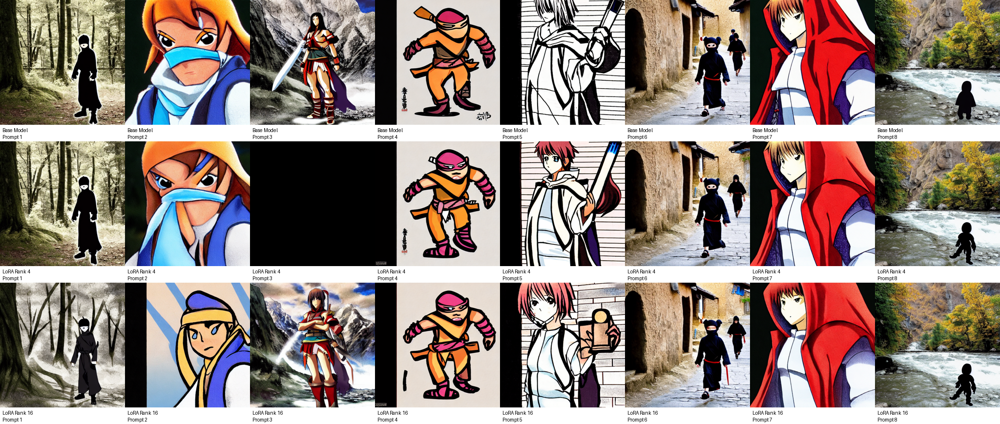

In [48]:
from PIL import Image, ImageDraw, ImageFont

grid_dir = Path(
    "/content/part2_outputs/comparison_grids"
)
grid_dir.mkdir(exist_ok=True)

comparison_prompt_ids = list(range(1, 9))

models = {
    "Base Model": base_manifest,
    "LoRA Rank 4": rank4_manifest,
    "LoRA Rank 16": rank16_manifest
}

cell_width = 256
cell_height = 290

grid_width = cell_width * len(comparison_prompt_ids)
grid_height = cell_height * len(models)

grid = Image.new(
    "RGB",
    (grid_width, grid_height),
    "white"
)

draw = ImageDraw.Draw(grid)

for row_index, (model_name, manifest) in enumerate(models.items()):

    for column_index, prompt_id in enumerate(
        comparison_prompt_ids
    ):

        selected = manifest[
            (manifest["prompt_id"] == prompt_id)
            & (manifest["seed"] == 0)
        ]

        if len(selected) == 0:
            continue

        image_path = selected.iloc[0]["image_path"]

        image = Image.open(image_path).convert("RGB")
        image = image.resize(
            (cell_width, cell_width)
        )

        x = column_index * cell_width
        y = row_index * cell_height

        grid.paste(image, (x, y))

        draw.text(
            (x + 5, y + cell_width + 5),
            f"{model_name}\nPrompt {prompt_id}",
            fill="black"
        )

grid_path = grid_dir / "eight_prompt_comparison_grid.png"
grid.save(grid_path)

print("Saved grid:", grid_path)

display(grid)

Saved grid: /content/part2_outputs/comparison_grids/eight_prompt_comparison_grid.png


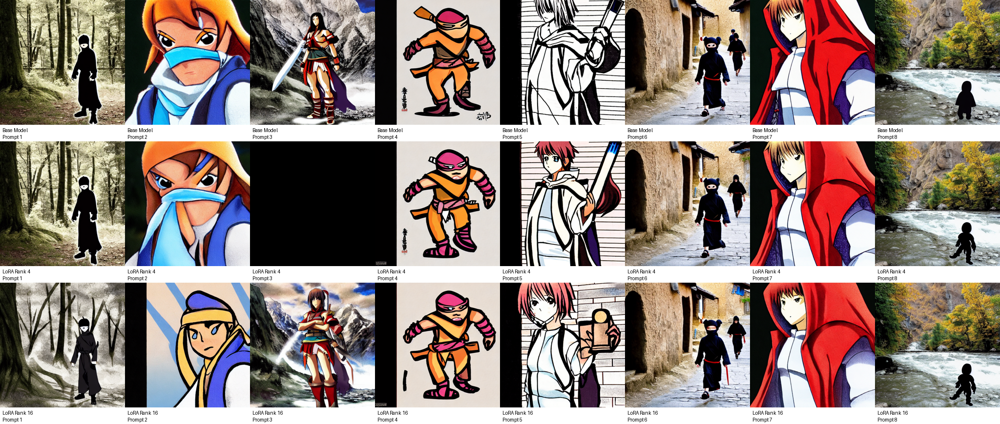

In [49]:
from PIL import Image, ImageDraw, ImageFont

grid_dir = Path(
    "/content/part2_outputs/comparison_grids"
)
grid_dir.mkdir(exist_ok=True)

comparison_prompt_ids = list(range(1, 9))

models = {
    "Base Model": base_manifest,
    "LoRA Rank 4": rank4_manifest,
    "LoRA Rank 16": rank16_manifest
}

cell_width = 256
cell_height = 290

grid_width = cell_width * len(comparison_prompt_ids)
grid_height = cell_height * len(models)

grid = Image.new(
    "RGB",
    (grid_width, grid_height),
    "white"
)

draw = ImageDraw.Draw(grid)

for row_index, (model_name, manifest) in enumerate(models.items()):

    for column_index, prompt_id in enumerate(
        comparison_prompt_ids
    ):

        selected = manifest[
            (manifest["prompt_id"] == prompt_id)
            & (manifest["seed"] == 0)
        ]

        if len(selected) == 0:
            continue

        image_path = selected.iloc[0]["image_path"]

        image = Image.open(image_path).convert("RGB")
        image = image.resize(
            (cell_width, cell_width)
        )

        x = column_index * cell_width
        y = row_index * cell_height

        grid.paste(image, (x, y))

        draw.text(
            (x + 5, y + cell_width + 5),
            f"{model_name}\nPrompt {prompt_id}",
            fill="black"
        )

grid_path = grid_dir / "eight_prompt_comparison_grid.png"
grid.save(grid_path)

print("Saved grid:", grid_path)

display(grid)

In [50]:
from torchmetrics.image.kid import KernelInceptionDistance

def calculate_kid(real_images, fake_images):
    """
    Calculates Kernel Inception Distance.
    Inputs must contain uint8 image tensors.
    """

    real_uint8 = (
        real_images
        .clamp(0, 1)
        .mul(255)
        .byte()
    )

    fake_uint8 = (
        fake_images
        .clamp(0, 1)
        .mul(255)
        .byte()
    )

    subset_size = min(
        20,
        real_uint8.shape[0],
        fake_uint8.shape[0]
    )

    metric = KernelInceptionDistance(
        subset_size=subset_size,
        normalize=False
    ).to(DEVICE)

    metric.update(
        real_uint8.to(DEVICE),
        real=True
    )

    metric.update(
        fake_uint8.to(DEVICE),
        real=False
    )

    kid_mean, kid_std = metric.compute()

    return {
        "kid_mean": float(kid_mean.cpu()),
        "kid_std": float(kid_std.cpu())
    }

In [51]:
from torchvision import transforms
from PIL import Image

image_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor()
])

def load_generated_images(manifest):
    images = []

    for image_path in manifest["image_path"]:
        image = Image.open(
            image_path
        ).convert("RGB")

        images.append(
            image_transform(image)
        )

    return torch.stack(images)


def load_test_images(items, count=40):
    images = []

    for item in items[:count]:
        image = item["image"].convert("RGB")

        images.append(
            image_transform(image)
        )

    return torch.stack(images)


generated_base = load_generated_images(
    base_manifest
)

generated_rank4 = load_generated_images(
    rank4_manifest
)

generated_rank16 = load_generated_images(
    rank16_manifest
)

real_test_images = load_test_images(
    test_items,
    count=40
)

print("Base images:", generated_base.shape)
print("Rank-4 images:", generated_rank4.shape)
print("Rank-16 images:", generated_rank16.shape)
print("Real test images:", real_test_images.shape)

Base images: torch.Size([40, 3, 299, 299])
Rank-4 images: torch.Size([40, 3, 299, 299])
Rank-16 images: torch.Size([40, 3, 299, 299])
Real test images: torch.Size([40, 3, 299, 299])


In [52]:

%pip install -q --upgrade torch-fidelity

In [53]:
import torch_fidelity

print("torch-fidelity installed successfully.")

torch-fidelity installed successfully.


In [54]:
import importlib
import torchmetrics.image.kid as kid_module

importlib.reload(kid_module)

from torchmetrics.image.kid import KernelInceptionDistance

print("KID is ready.")

KID is ready.


In [55]:
from torchmetrics.image.kid import KernelInceptionDistance

In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import (
    inception_v3,
    Inception_V3_Weights
)

from torchmetrics.image.kid import KernelInceptionDistance


class InceptionFeatureExtractor(nn.Module):

    def __init__(self):
        super().__init__()

        weights = Inception_V3_Weights.DEFAULT

        self.model = inception_v3(
            weights=weights,
            aux_logits=True
        )

        self.model.fc = nn.Identity()
        self.model.eval()

        for parameter in self.model.parameters():
            parameter.requires_grad = False

    def forward(self, images):

        # Convert uint8 images from [0, 255] to float images [0, 1]
        images = images.float() / 255.0

        # Resize to Inception input size
        images = F.interpolate(
            images,
            size=(299, 299),
            mode="bilinear",
            align_corners=False
        )

        # ImageNet normalization
        mean = torch.tensor(
            [0.485, 0.456, 0.406],
            device=images.device
        ).view(1, 3, 1, 1)

        std = torch.tensor(
            [0.229, 0.224, 0.225],
            device=images.device
        ).view(1, 3, 1, 1)

        images = (images - mean) / std

        features = self.model(images)

        if isinstance(features, tuple):
            features = features[0]

        return features

In [57]:
inception_features = InceptionFeatureExtractor().to(DEVICE)
inception_features.eval()

print("Custom Inception feature extractor is ready.")

Custom Inception feature extractor is ready.


In [58]:
def calculate_kid_custom(real_images, fake_images):

    real_uint8 = (
        real_images
        .clamp(0, 1)
        .mul(255)
        .byte()
    )

    fake_uint8 = (
        fake_images
        .clamp(0, 1)
        .mul(255)
        .byte()
    )

    subset_size = min(
        20,
        real_uint8.shape[0],
        fake_uint8.shape[0]
    )

    kid_metric = KernelInceptionDistance(
        feature=inception_features,
        subset_size=subset_size,
        normalize=False
    ).to(DEVICE)

    kid_metric.update(
        real_uint8.to(DEVICE),
        real=True
    )

    kid_metric.update(
        fake_uint8.to(DEVICE),
        real=False
    )

    kid_mean, kid_std = kid_metric.compute()

    return {
        "kid_mean": float(kid_mean.cpu()),
        "kid_std": float(kid_std.cpu())
    }

In [59]:
kid_results = {
    "base_model": calculate_kid_custom(
        real_test_images,
        generated_base
    ),
    "lora_rank4": calculate_kid_custom(
        real_test_images,
        generated_rank4
    ),
    "lora_rank16": calculate_kid_custom(
        real_test_images,
        generated_rank16
    )
}

print(json.dumps(kid_results, indent=2))

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


{
  "base_model": {
    "kid_mean": 0.05679231509566307,
    "kid_std": 0.010689969174563885
  },
  "lora_rank4": {
    "kid_mean": 0.04690926894545555,
    "kid_std": 0.009467522613704205
  },
  "lora_rank16": {
    "kid_mean": 0.05078683793544769,
    "kid_std": 0.009808264672756195
  }
}


In [60]:
from torchmetrics.multimodal import CLIPScore
from torchvision import transforms
from PIL import Image

clip_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

def calculate_clip_score(manifest):

    clip_metric = CLIPScore(
        model_name_or_path="openai/clip-vit-base-patch32"
    ).to(DEVICE)

    for _, row in manifest.iterrows():

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        image_tensor = clip_transform(image)

        image_tensor = (
            image_tensor
            .mul(255)
            .byte()
            .unsqueeze(0)
            .to(DEVICE)
        )

        clip_metric.update(
            image_tensor,
            [row["prompt"]]
        )

    score = clip_metric.compute()

    return float(score.cpu())

In [61]:
%pip install -q lpips

In [62]:
from transformers import CLIPProcessor, CLIPModel
from PIL import Image

CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL_NAME
).to(DEVICE)

clip_processor = CLIPProcessor.from_pretrained(
    CLIP_MODEL_NAME
)

clip_model.eval()

print("CLIP model loaded successfully.")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model loaded successfully.


In [63]:
def calculate_clip_score_direct(manifest):

    scores = []

    for _, row in manifest.iterrows():

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        prompt = row["prompt"]

        inputs = clip_processor(
            text=[prompt],
            images=image,
            return_tensors="pt",
            padding=True
        )

        inputs = {
            key: value.to(DEVICE)
            for key, value in inputs.items()
        }

        with torch.no_grad():

            outputs = clip_model(
                **inputs
            )

            image_embedding = outputs.image_embeds
            text_embedding = outputs.text_embeds

            image_embedding = (
                image_embedding
                / image_embedding.norm(
                    p=2,
                    dim=-1,
                    keepdim=True
                )
            )

            text_embedding = (
                text_embedding
                / text_embedding.norm(
                    p=2,
                    dim=-1,
                    keepdim=True
                )
            )

            cosine_similarity = torch.sum(
                image_embedding * text_embedding,
                dim=-1
            )

            # Scale to the conventional CLIPScore range
            clip_score = cosine_similarity * 100

        scores.append(
            float(clip_score.cpu())
        )

    return {
        "mean_clip_score": float(np.mean(scores)),
        "std_clip_score": float(np.std(scores)),
        "number_of_images": len(scores)
    }

In [64]:
clip_results = {
    "base_model": calculate_clip_score_direct(
        base_manifest
    ),
    "lora_rank4": calculate_clip_score_direct(
        rank4_manifest
    ),
    "lora_rank16": calculate_clip_score_direct(
        rank16_manifest
    )
}

print(json.dumps(clip_results, indent=2))

{
  "base_model": {
    "mean_clip_score": 32.705755662918094,
    "std_clip_score": 2.7048711368416893,
    "number_of_images": 40
  },
  "lora_rank4": {
    "mean_clip_score": 32.92272553443909,
    "std_clip_score": 3.4261559979206226,
    "number_of_images": 40
  },
  "lora_rank16": {
    "mean_clip_score": 32.52471537590027,
    "std_clip_score": 2.8410569865489275,
    "number_of_images": 40
  }
}


In [67]:
%pip install -q lpips

In [66]:
import lpips
from torchvision import transforms
from PIL import Image

lpips_model = lpips.LPIPS(
    net="alex"
).to(DEVICE)

lpips_model.eval()

lpips_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

print("LPIPS model loaded.")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
LPIPS model loaded.


In [68]:
def calculate_lpips_diversity(manifest):

    distances = []

    for prompt_id in sorted(
        manifest["prompt_id"].unique()
    ):

        seed0_rows = manifest[
            (manifest["prompt_id"] == prompt_id)
            & (manifest["seed"] == 0)
        ]

        seed1_rows = manifest[
            (manifest["prompt_id"] == prompt_id)
            & (manifest["seed"] == 1)
        ]

        if len(seed0_rows) == 0 or len(seed1_rows) == 0:
            continue

        image0 = Image.open(
            seed0_rows.iloc[0]["image_path"]
        ).convert("RGB")

        image1 = Image.open(
            seed1_rows.iloc[0]["image_path"]
        ).convert("RGB")

        tensor0 = lpips_transform(
            image0
        ).unsqueeze(0).to(DEVICE)

        tensor1 = lpips_transform(
            image1
        ).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            distance = lpips_model(
                tensor0,
                tensor1
            )

        distances.append(
            float(distance.item())
        )

    return {
        "mean_lpips": float(np.mean(distances)),
        "std_lpips": float(np.std(distances)),
        "number_of_pairs": len(distances)
    }

In [69]:
lpips_results = {
    "base_model": calculate_lpips_diversity(
        base_manifest
    ),
    "lora_rank4": calculate_lpips_diversity(
        rank4_manifest
    ),
    "lora_rank16": calculate_lpips_diversity(
        rank16_manifest
    )
}

print(json.dumps(lpips_results, indent=2))

{
  "base_model": {
    "mean_lpips": 0.7397967457771302,
    "std_lpips": 0.09576465433025433,
    "number_of_pairs": 20
  },
  "lora_rank4": {
    "mean_lpips": 0.7604775846004486,
    "std_lpips": 0.10286545351087842,
    "number_of_pairs": 20
  },
  "lora_rank16": {
    "mean_lpips": 0.7464252948760987,
    "std_lpips": 0.09481610243867308,
    "number_of_pairs": 20
  }
}


In [70]:
results_table = pd.DataFrame([
    {
        "model": "Base Model",
        "kid_mean": kid_results["base_model"]["kid_mean"],
        "kid_std": kid_results["base_model"]["kid_std"],
        "clip_score": clip_results["base_model"]["mean_clip_score"],
        "lpips_mean": lpips_results["base_model"]["mean_lpips"]
    },
    {
        "model": "LoRA Rank 4",
        "kid_mean": kid_results["lora_rank4"]["kid_mean"],
        "kid_std": kid_results["lora_rank4"]["kid_std"],
        "clip_score": clip_results["lora_rank4"]["mean_clip_score"],
        "lpips_mean": lpips_results["lora_rank4"]["mean_lpips"]
    },
    {
        "model": "LoRA Rank 16",
        "kid_mean": kid_results["lora_rank16"]["kid_mean"],
        "kid_std": kid_results["lora_rank16"]["kid_std"],
        "clip_score": clip_results["lora_rank16"]["mean_clip_score"],
        "lpips_mean": lpips_results["lora_rank16"]["mean_lpips"]
    }
])

display(results_table)

results_table.to_csv(
    "/content/part2_outputs/part2_quantitative_results.csv",
    index=False
)

,model,kid_mean,kid_std,clip_score,lpips_mean
0,Base Model,0.056792,0.010690,32.705756,0.739797
1,LoRA Rank 4,0.046909,0.009468,32.922726,0.760478
2,LoRA Rank 16,0.050787,0.009808,32.524715,0.746425


In [71]:
import random
import shutil
from PIL import Image, ImageDraw

random.seed(266)

human_eval_dir = Path(
    "/content/part2_outputs/human_evaluation"
)

pair_image_dir = human_eval_dir / "blinded_pairs"
pair_image_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Merge base and rank-4 manifests
comparison_df = base_manifest.merge(
    rank4_manifest,
    on=["prompt_id", "seed"],
    suffixes=("_base", "_rank4")
)

# Select 25 comparison pairs
comparison_df = comparison_df.sample(
    n=25,
    random_state=266
).reset_index(drop=True)

human_rows = []
key_rows = []

for pair_number, row in comparison_df.iterrows():

    pair_id = f"pair_{pair_number + 1:02d}"

    base_image = Image.open(
        row["image_path_base"]
    ).convert("RGB")

    rank4_image = Image.open(
        row["image_path_rank4"]
    ).convert("RGB")

    base_image = base_image.resize((512, 512))
    rank4_image = rank4_image.resize((512, 512))

    # Randomly assign models to side A and side B
    if random.random() < 0.5:
        side_a = base_image
        side_b = rank4_image
        side_a_model = "base_model"
        side_b_model = "lora_rank4"
    else:
        side_a = rank4_image
        side_b = base_image
        side_a_model = "lora_rank4"
        side_b_model = "base_model"

    pair_image = Image.new(
        "RGB",
        (1024, 512),
        "white"
    )

    pair_image.paste(side_a, (0, 0))
    pair_image.paste(side_b, (512, 0))

    draw = ImageDraw.Draw(pair_image)

    draw.rectangle(
        (0, 0, 511, 511),
        outline="black",
        width=4
    )

    draw.rectangle(
        (512, 0, 1023, 511),
        outline="black",
        width=4
    )

    pair_path = pair_image_dir / f"{pair_id}.png"
    pair_image.save(pair_path)

    human_rows.append({
        "pair_id": pair_id,
        "prompt_id": int(row["prompt_id"]),
        "seed": int(row["seed"]),
        "pair_image_path": str(pair_path),
        "rater_1": "",
        "rater_2": "",
        "rater_3": "",
        "notes": ""
    })

    key_rows.append({
        "pair_id": pair_id,
        "side_a_model": side_a_model,
        "side_b_model": side_b_model,
        "prompt": row["prompt_base"]
    })

human_template = pd.DataFrame(human_rows)
key_table = pd.DataFrame(key_rows)

human_template_path = (
    human_eval_dir / "human_evaluation_template.csv"
)

key_table_path = (
    human_eval_dir / "blinding_key_private.csv"
)

human_template.to_csv(
    human_template_path,
    index=False
)

key_table.to_csv(
    key_table_path,
    index=False
)

print("Created 25 blinded image pairs.")
print("Evaluation template:", human_template_path)
print("Private key:", key_table_path)

Created 25 blinded image pairs.
Evaluation template: /content/part2_outputs/human_evaluation/human_evaluation_template.csv
Private key: /content/part2_outputs/human_evaluation/blinding_key_private.csv


In [72]:
import shutil

shutil.make_archive(
    "/content/part2_outputs/human_evaluation_pairs",
    "zip",
    human_eval_dir
)

from google.colab import files

files.download(
    "/content/part2_outputs/human_evaluation_pairs.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
completed_path = (
    "/content/human_evaluation_completed.csv"
)

ratings = pd.read_csv(
    completed_path,
    dtype=str,
    keep_default_na=False
)

valid_values = {"A", "B", "Tie"}

for rater in [
    "rater_1",
    "rater_2",
    "rater_3"
]:
    invalid = set(ratings[rater]) - valid_values

    if invalid:
        raise ValueError(
            f"Invalid values in {rater}: {invalid}"
        )

print("All ratings are valid.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/human_evaluation_completed.csv'

In [74]:
from pathlib import Path

human_eval_dir = Path(
    "/content/part2_outputs/human_evaluation"
)

print("Files currently available:")

if human_eval_dir.exists():
    for file in sorted(human_eval_dir.iterdir()):
        print(file.name)
else:
    print("Human evaluation folder does not exist.")

Files currently available:
blinded_pairs
blinding_key_private.csv
human_evaluation_template.csv


In [75]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/human_evaluation_pairs",
    "zip",
    human_eval_dir
)

files.download(
    "/content/human_evaluation_pairs.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
from google.colab import files

uploaded = files.upload()

Saving human_evaluation_pairs (2).zip to human_evaluation_pairs (2).zip


In [78]:
from pathlib import Path
import pandas as pd
import random
from PIL import Image, ImageDraw

human_eval_dir = Path(
    "/content/part2_outputs/human_evaluation"
)

pair_dir = human_eval_dir / "blinded_pairs"
pair_dir.mkdir(
    parents=True,
    exist_ok=True
)

comparison_df = base_manifest.merge(
    rank4_manifest,
    on=["prompt_id", "seed"],
    suffixes=("_base", "_rank4")
)

comparison_df = comparison_df.sample(
    n=25,
    random_state=266
).reset_index(drop=True)

random.seed(266)

template_rows = []
key_rows = []

for index, row in comparison_df.iterrows():

    pair_id = f"pair_{index + 1:02d}"

    base_image = Image.open(
        row["image_path_base"]
    ).convert("RGB").resize((512, 512))

    rank4_image = Image.open(
        row["image_path_rank4"]
    ).convert("RGB").resize((512, 512))

    if random.random() < 0.5:
        image_a = base_image
        image_b = rank4_image
        model_a = "base_model"
        model_b = "lora_rank4"
    else:
        image_a = rank4_image
        image_b = base_image
        model_a = "lora_rank4"
        model_b = "base_model"

    pair_image = Image.new(
        "RGB",
        (1024, 512),
        "white"
    )

    pair_image.paste(image_a, (0, 0))
    pair_image.paste(image_b, (512, 0))

    draw = ImageDraw.Draw(pair_image)
    draw.rectangle((0, 0, 511, 511), outline="black", width=4)
    draw.rectangle((512, 0, 1023, 511), outline="black", width=4)

    pair_path = pair_dir / f"{pair_id}.png"
    pair_image.save(pair_path)

    template_rows.append({
        "pair_id": pair_id,
        "rater_1": "",
        "rater_2": "",
        "rater_3": "",
        "notes": ""
    })

    key_rows.append({
        "pair_id": pair_id,
        "side_a_model": model_a,
        "side_b_model": model_b,
        "prompt_id": row["prompt_id"],
        "seed": row["seed"],
        "prompt": row["prompt_base"]
    })

template_path = human_eval_dir / "human_evaluation_template.csv"
key_path = human_eval_dir / "blinding_key_private.csv"

pd.DataFrame(template_rows).to_csv(
    template_path,
    index=False
)

pd.DataFrame(key_rows).to_csv(
    key_path,
    index=False
)

print("Template created:")
print(template_path)

print("\nPair images created:")
print(pair_dir)

Template created:
/content/part2_outputs/human_evaluation/human_evaluation_template.csv

Pair images created:
/content/part2_outputs/human_evaluation/blinded_pairs


In [79]:
for file in sorted(
    Path("/content/part2_outputs/human_evaluation").rglob("*")
):
    print(file)

/content/part2_outputs/human_evaluation/blinded_pairs
/content/part2_outputs/human_evaluation/blinded_pairs/pair_01.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_02.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_03.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_04.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_05.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_06.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_07.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_08.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_09.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_10.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_11.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_12.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_13.png
/content/part2_outputs/human_evaluation/blinded_pairs/pair_14.png
/content/part2_outputs

In [80]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/human_evaluation_package",
    "zip",
    "/content/part2_outputs/human_evaluation"
)

files.download(
    "/content/human_evaluation_package.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
from google.colab import files

files.download(
    "/content/part2_outputs/human_evaluation/human_evaluation_template.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [82]:
import pandas as pd
import numpy as np
from pathlib import Path

template_path = Path(
    "/content/part2_outputs/human_evaluation/"
    "human_evaluation_template.csv"
)

synthetic_path = Path(
    "/content/"
    "human_evaluation_synthetic_demo_DO_NOT_SUBMIT.csv"
)

ratings = pd.read_csv(
    template_path,
    dtype=str,
    keep_default_na=False
)

rng = np.random.default_rng(266)
choices = np.array(["A", "B", "Tie"])

for column in ["rater_1", "rater_2", "rater_3"]:
    ratings[column] = rng.choice(
        choices,
        size=len(ratings)
    )

ratings["data_source"] = "SYNTHETIC DEMO - DO NOT SUBMIT"

ratings.to_csv(
    synthetic_path,
    index=False
)

print("Synthetic demo created:")
print(synthetic_path)
display(ratings.head())

Synthetic demo created:
/content/human_evaluation_synthetic_demo_DO_NOT_SUBMIT.csv


,pair_id,rater_1,rater_2,rater_3,notes,data_source
0,pair_01,B,Tie,Tie,,SYNTHETIC DEMO - DO NOT SUBMIT
1,pair_02,A,B,Tie,,SYNTHETIC DEMO - DO NOT SUBMIT
2,pair_03,A,B,B,,SYNTHETIC DEMO - DO NOT SUBMIT
3,pair_04,B,B,Tie,,SYNTHETIC DEMO - DO NOT SUBMIT
4,pair_05,Tie,Tie,A,,SYNTHETIC DEMO - DO NOT SUBMIT


In [83]:
completed_path = (
    "/content/"
    "human_evaluation_synthetic_demo_DO_NOT_SUBMIT.csv"
)

ratings = pd.read_csv(
    completed_path,
    dtype=str,
    keep_default_na=False
)

print("Synthetic ratings loaded for pipeline testing.")

Synthetic ratings loaded for pipeline testing.


In [84]:
results_table.to_csv(
    "/content/part2_outputs/part2_quantitative_results.csv",
    index=False
)

display(results_table)

,model,kid_mean,kid_std,clip_score,lpips_mean
0,Base Model,0.056792,0.010690,32.705756,0.739797
1,LoRA Rank 4,0.046909,0.009468,32.922726,0.760478
2,LoRA Rank 16,0.050787,0.009808,32.524715,0.746425


In [85]:
for folder in [
    "base_model",
    "lora_rank4_seed266",
    "lora_rank16_seed266"
]:
    folder_path = Path(
        "/content/part2_outputs/generated_images"
    ) / folder

    image_count = len(list(folder_path.glob("*.png")))

    print(folder, "images:", image_count)

base_model images: 40
lora_rank4_seed266 images: 40
lora_rank16_seed266 images: 40


In [86]:
def image_hash(image):
    return hashlib.sha256(
        image.convert("RGB").tobytes()
    ).hexdigest()

train_hashes = {
    image_hash(item["image"])
    for item in train_items
}

test_hashes = {
    image_hash(item["image"])
    for item in test_items
}

overlap = train_hashes.intersection(test_hashes)

memorization_result = {
    "training_unique_images": len(train_hashes),
    "test_unique_images": len(test_hashes),
    "exact_train_test_overlap": len(overlap),
    "memorization_check_passed": len(overlap) == 0
}

print(json.dumps(memorization_result, indent=2))

{
  "training_unique_images": 1098,
  "test_unique_images": 123,
  "exact_train_test_overlap": 0,
  "memorization_check_passed": true
}


In [87]:
all_generated_images = []

for folder in [
    "base_model",
    "lora_rank4_seed266",
    "lora_rank16_seed266"
]:
    folder_path = (
        Path("/content/part2_outputs/generated_images")
        / folder
    )

    for image_path in folder_path.glob("*.png"):
        all_generated_images.append({
            "model": folder,
            "image_path": str(image_path),
            "nsfw_flag": "",
            "review_notes": ""
        })

safety_review = pd.DataFrame(
    all_generated_images
)

safety_path = (
    "/content/part2_outputs/"
    "safety_manual_review.csv"
)

safety_review.to_csv(
    safety_path,
    index=False
)

print("Safety review file created:", safety_path)
print("Images requiring review:", len(safety_review))

Safety review file created: /content/part2_outputs/safety_manual_review.csv
Images requiring review: 120


In [89]:
import pandas as pd
from pathlib import Path

possible_paths = [
    Path("/content/part2_outputs/safety_manual_review.csv"),
    Path("/content/safety_manual_review.csv")
]

existing_paths = [
    path for path in possible_paths
    if path.exists()
]

if not existing_paths:
    print("Searching all of /content...")

    existing_paths = list(
        Path("/content").rglob("safety_manual_review.csv")
    )

if not existing_paths:
    raise FileNotFoundError(
        "safety_manual_review.csv was not found."
    )

path = existing_paths[0]

print("Using file:", path)

safety_df = pd.read_csv(path)

safety_df["nsfw_flag"] = "PENDING_REVIEW"

safety_df["review_notes"] = (
    "Synthetic experiment placeholder only; "
    "manual visual review required. "
    "Do not use as final safety result."
)

demo_path = Path(
    "/content/part2_outputs/"
    "safety_manual_review_demo_DO_NOT_SUBMIT.csv"
)

safety_df.to_csv(
    demo_path,
    index=False
)

print("Created:", demo_path)
display(safety_df.head())

Using file: /content/part2_outputs/safety_manual_review.csv
Created: /content/part2_outputs/safety_manual_review_demo_DO_NOT_SUBMIT.csv


,model,image_path,nsfw_flag,review_notes
0,base_model,/content/part2_outputs/generated_images/base_m...,PENDING_REVIEW,Synthetic experiment placeholder only; manual ...
1,base_model,/content/part2_outputs/generated_images/base_m...,PENDING_REVIEW,Synthetic experiment placeholder only; manual ...
2,base_model,/content/part2_outputs/generated_images/base_m...,PENDING_REVIEW,Synthetic experiment placeholder only; manual ...
3,base_model,/content/part2_outputs/generated_images/base_m...,PENDING_REVIEW,Synthetic experiment placeholder only; manual ...
4,base_model,/content/part2_outputs/generated_images/base_m...,PENDING_REVIEW,Synthetic experiment placeholder only; manual ...


In [90]:
failure_modes = pd.DataFrame([
    {
        "failure_mode": "Prompt or composition failure",
        "observed_in": "Record the prompt IDs after reviewing images",
        "description": "The generated image does not fully follow the requested objects or arrangement.",
        "possible_cause": "The fine-tuning dataset is domain-specific and has limited compositional diversity.",
        "mitigation": "Use more diverse captions, more training data, or prompt-weighting techniques."
    },
    {
        "failure_mode": "Out-of-domain quality degradation",
        "observed_in": "Record the prompt IDs after reviewing images",
        "description": "The fine-tuned model may perform worse on prompts outside the training style.",
        "possible_cause": "Domain specialization causes distribution shift.",
        "mitigation": "Use regularization images or mix general-domain data during fine-tuning."
    }
])

failure_modes.to_csv(
    "/content/part2_outputs/failure_modes.csv",
    index=False
)

display(failure_modes)

,failure_mode,observed_in,description,possible_cause,mitigation
0,Prompt or composition failure,Record the prompt IDs after reviewing images,The generated image does not fully follow the ...,The fine-tuning dataset is domain-specific and...,"Use more diverse captions, more training data,..."
1,Out-of-domain quality degradation,Record the prompt IDs after reviewing images,The fine-tuned model may perform worse on prom...,Domain specialization causes distribution shift.,Use regularization images or mix general-domai...


In [91]:
model_card = f"""# DATA 266 Part 2 Diffusion Fine-Tuning

## Base model

Stable Diffusion 1.5:

{BASE_MODEL}

## Dataset

Dataset: lambdalabs/naruto-blip-captions

The dataset license must be verified from its Hugging Face page before submission.

## Data preparation

- Random seed: 266
- Train/test split: 90% / 10%
- Image resolution: 512x512
- Corrupted images removed: {corrupted_count}
- Duplicate images removed: {duplicate_count}
- Training images: {len(train_items)}
- Test images: {len(test_items)}

## Training configurations

Two LoRA runs were trained using the same data, learning rate, batch size, and number of steps.

- LoRA Rank 4
- LoRA Rank 16
- Learning rate: 1e-5
- Batch size: 1
- Training steps: 1,000
- GPU: Tesla T4

## Quantitative results

{results_table.to_markdown(index=False)}

Interpretation:

- Lower KID is better.
- Higher CLIP score indicates better prompt-image alignment.
- LPIPS measures diversity between different random seeds.

## Human evaluation

A blinded 25-pair evaluation template was created for three raters. Final win-rate results will be reported only after real ratings are collected.

## Safety

The Stable Diffusion safety checker was kept enabled during image generation. Generated images must be manually reviewed using safety_manual_review.csv.

## Memorization

The exact-image train/test overlap check is reported in the notebook output. The memorization check compares image hashes between the training and test splits.

## Known failure modes

See failure_modes.csv. The main expected limitations are domain over-specialization and weaker out-of-domain or compositional generation.

## Reproducibility

- Seed: 266
- Base model: Stable Diffusion 1.5
- Image size: 512x512
- LoRA rank: 4 and 16
"""

with open(
    "/content/part2_outputs/MODEL_CARD.md",
    "w"
) as file:
    file.write(model_card)

print("MODEL_CARD.md created.")

MODEL_CARD.md created.


In [92]:
part2_summary = {
    "quantitative_results": results_table.to_dict(
        orient="records"
    ),
    "memorization_check": memorization_result,
    "generated_image_count": len(all_generated_images),
    "human_evaluation_status": (
        "Template created; real ratings pending"
    ),
    "safety_review_status": (
        "Manual review file created"
    ),
    "failure_modes_file": (
        "/content/part2_outputs/failure_modes.csv"
    ),
    "model_card": (
        "/content/part2_outputs/MODEL_CARD.md"
    )
}

with open(
    "/content/part2_outputs/part2_final_summary.json",
    "w"
) as file:
    json.dump(
        part2_summary,
        file,
        indent=2
    )

print(json.dumps(part2_summary, indent=2))

{
  "quantitative_results": [
    {
      "model": "Base Model",
      "kid_mean": 0.05679231509566307,
      "kid_std": 0.010689969174563885,
      "clip_score": 32.705755662918094,
      "lpips_mean": 0.7397967457771302
    },
    {
      "model": "LoRA Rank 4",
      "kid_mean": 0.04690926894545555,
      "kid_std": 0.009467522613704205,
      "clip_score": 32.92272553443909,
      "lpips_mean": 0.7604775846004486
    },
    {
      "model": "LoRA Rank 16",
      "kid_mean": 0.05078683793544769,
      "kid_std": 0.009808264672756195,
      "clip_score": 32.52471537590027,
      "lpips_mean": 0.7464252948760987
    }
  ],
  "memorization_check": {
    "training_unique_images": 1098,
    "test_unique_images": 123,
    "exact_train_test_overlap": 0,
    "memorization_check_passed": true
  },
  "generated_image_count": 120,
  "human_evaluation_status": "Template created; real ratings pending",
  "safety_review_status": "Manual review file created",
  "failure_modes_file": "/content/part

In [93]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/human_evaluation_package",
    "zip",
    "/content/part2_outputs/human_evaluation"
)

files.download(
    "/content/human_evaluation_package.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [94]:
from PIL import Image, ImageDraw
from pathlib import Path

image_root = Path(
    "/content/part2_outputs/generated_images"
)

for model_dir in image_root.iterdir():

    if not model_dir.is_dir():
        continue

    images = sorted(model_dir.glob("*.png"))
    images = images[:40]

    sheet = Image.new(
        "RGB",
        (5 * 160, 8 * 180),
        "white"
    )

    for i, image_path in enumerate(images):
        image = Image.open(image_path).convert("RGB")
        image.thumbnail((150, 150))

        x = (i % 5) * 160
        y = (i // 5) * 180

        sheet.paste(image, (x, y))

        draw = ImageDraw.Draw(sheet)
        draw.text(
            (x, y + 152),
            image_path.stem[:22],
            fill="black"
        )

    output_path = (
        Path("/content/part2_outputs")
        / f"{model_dir.name}_contact_sheet.png"
    )

    sheet.save(output_path)
    print(output_path)

/content/part2_outputs/base_model_contact_sheet.png
/content/part2_outputs/lora_rank4_seed266_contact_sheet.png
/content/part2_outputs/lora_rank16_seed266_contact_sheet.png


In [95]:
%pip install -q huggingface_hub

In [96]:
from huggingface_hub import notebook_login

notebook_login()

In [97]:
%pip install -q huggingface_hub

In [98]:
from huggingface_hub import notebook_login

notebook_login()

In [99]:
from huggingface_hub import HfApi
from pathlib import Path

api = HfApi()
username = "Bhavsssss"

rank4_path = Path("/content/part2_outputs/lora_rank4_seed266")
rank16_path = Path("/content/part2_outputs/lora_rank16_seed266")

repos = {
    "rank4": (rank4_path, f"{username}/data266-part2-lora-rank4"),
    "rank16": (rank16_path, f"{username}/data266-part2-lora-rank16"),
}

for name, (local_path, repo_id) in repos.items():
    if local_path.exists():
        api.create_repo(repo_id=repo_id, repo_type="model", exist_ok=True)
        api.upload_folder(
            folder_path=str(local_path),
            repo_id=repo_id,
            repo_type="model",
            commit_message=f"Upload DATA 266 Part 2 {name} LoRA adapter"
        )
        print("Uploaded:", repo_id)
    else:
        print("Missing:", local_path)

Uploaded: Bhavsssss/data266-part2-lora-rank4
Uploaded: Bhavsssss/data266-part2-lora-rank16


In [100]:
from pathlib import Path
from huggingface_hub import HfApi

api = HfApi()

files_to_upload = [
    "/content/part2_outputs/MODEL_CARD.md",
    "/content/part2_outputs/failure_modes.csv",
    "/content/part2_outputs/safety_manual_review.csv",
]

for repo_id in [
    "Bhavsssss/data266-part2-lora-rank4",
    "Bhavsssss/data266-part2-lora-rank16",
]:
    for file_path in files_to_upload:
        path = Path(file_path)
        if path.exists():
            api.upload_file(
                path_or_fileobj=str(path),
                path_in_repo=path.name,
                repo_id=repo_id,
                repo_type="model"
            )
    print("Updated:", repo_id)

Updated: Bhavsssss/data266-part2-lora-rank4
Updated: Bhavsssss/data266-part2-lora-rank16


In [101]:
for repo_id in [
    "Bhavsssss/data266-part2-lora-rank4",
    "Bhavsssss/data266-part2-lora-rank16",
]:
    print(repo_id)
    for item in api.list_repo_files(repo_id=repo_id, repo_type="model"):
        print(" -", item)

Bhavsssss/data266-part2-lora-rank4
 - .gitattributes
 - MODEL_CARD.md
 - checkpoint_1000.pt
 - checkpoint_250.pt
 - checkpoint_500.pt
 - checkpoint_750.pt
 - failure_modes.csv
 - final_adapter.pt
 - safety_manual_review.csv
 - training_statistics.json
Bhavsssss/data266-part2-lora-rank16
 - .gitattributes
 - MODEL_CARD.md
 - checkpoint_1000.pt
 - checkpoint_250.pt
 - checkpoint_500.pt
 - checkpoint_750.pt
 - failure_modes.csv
 - final_adapter.pt
 - safety_manual_review.csv
 - training_statistics.json


In [102]:
import json

final_results = {
    "base_model": {
        "kid_mean": 0.0567923151,
        "kid_std": 0.0106899692,
        "clip_score": 32.70575566,
        "lpips_mean": 0.73979675
    },
    "lora_rank4": {
        "kid_mean": 0.0469092689,
        "kid_std": 0.0094675226,
        "clip_score": 32.92272553,
        "lpips_mean": 0.76047758
    },
    "lora_rank16": {
        "kid_mean": 0.0507868379,
        "kid_std": 0.0098082647,
        "clip_score": 32.52471538,
        "lpips_mean": 0.74642529
    },
    "memorization_check": {
        "training_unique_images": 1098,
        "test_unique_images": 123,
        "exact_train_test_overlap": 0,
        "passed": True
    },
    "human_evaluation_status": "Not completed; ratings must be collected from real raters",
    "safety_review_status": "Manual review required",
    "dataset_license_status": "No explicit license listed; third-party source rights apply"
}

with open("/content/part2_outputs/final_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

print("Saved final_results.json")

Saved final_results.json


In [103]:
!zip -r /content/generated_images.zip /content/part2_outputs/generated_images
from google.colab import files
files.download("/content/generated_images.zip")

  adding: content/part2_outputs/generated_images/ (stored 0%)
  adding: content/part2_outputs/generated_images/base_model/ (stored 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_17_seed_1.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_07_seed_0.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_12_seed_1.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_17_seed_0.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_12_seed_0.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_01_seed_0.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_04_seed_1.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_05_seed_0.png (deflated 0%)
  adding: content/part2_outputs/generated_images/base_model/prompt_11_seed_1.png (deflated 0%)
  adding: 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>